# Interprétation du modèle (SHAP)

Pourquoi le modèle annonce-t-il telle probabilité ? Les valeurs SHAP décomposent chaque prédiction en contributions additives, une par variable :

$$\text{logit}(p) = \text{valeur de base} + \sum_j \text{contribution}_j$$

Une contribution positive pousse vers une victoire T, une contribution négative vers une victoire CT. Les valeurs sont exactes : LightGBM les calcule directement sur ses arbres (algorithme TreeSHAP, option `pred_contrib=True`).

L'analyse porte sur le jeu de test, avec le modèle final.

## 0. Imports, modèle et données

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from src.config import SEED, TARGET
from src.rounds import load_processed
from src.train import MODEL_PATH, load_model, train_final_model
from src.tuning import load_best_params
from src.explain import BASE, explain_row, global_importance, shap_values, transformed_features
from src.viz import COLOR_CT, COLOR_T, COLOR_TEXT, COLOR_TEXT_MUTED, save_fig, set_style

set_style()
df = load_processed()
train = df[df["split"] == "train"].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)
model = load_model() if MODEL_PATH.exists() else train_final_model(train, load_best_params())

shap_test = shap_values(model, test)
features_test = transformed_features(model, test)
features_test["map"] = test["map"].astype(str).to_numpy()
check = np.abs(1 / (1 + np.exp(-shap_test.sum(axis=1))) - model.predict_proba(test)[:, 1]).max()
print(f"{len(test):,} snapshots expliqués | écart maximal somme SHAP / prédiction : {check:.1e}")

24,978 snapshots expliqués | écart maximal somme SHAP / prédiction : 2.7e-15


## 1. Importance globale

Moyenne de la valeur absolue des contributions sur le test : de combien, en moyenne, chaque variable déplace la prédiction.

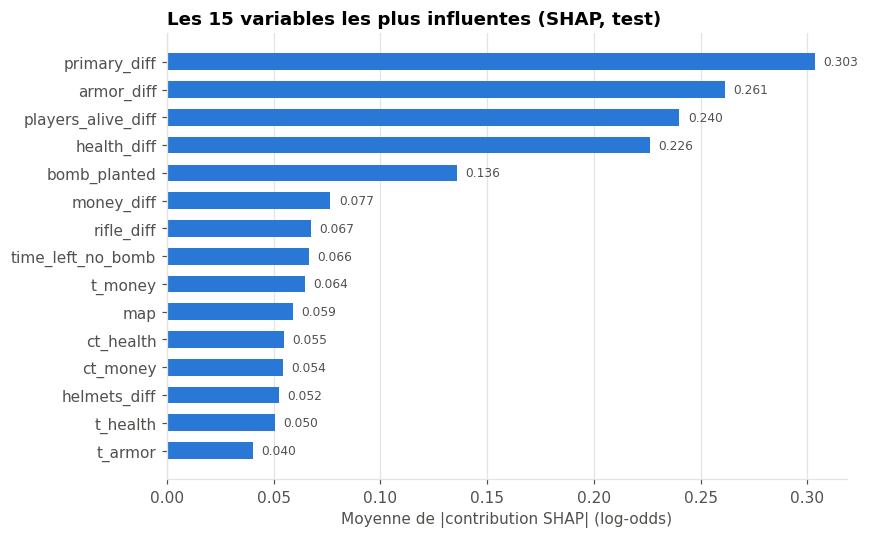

Part de l'influence totale des 5 premières variables : 53%


In [2]:
importance = global_importance(shap_test)
top = importance.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=COLOR_CT, height=0.6)
for y, v in enumerate(top.values):
    ax.text(v + 0.004, y, f"{v:.3f}", va="center", fontsize=8, color=COLOR_TEXT_MUTED)
ax.set_xlabel("Moyenne de |contribution SHAP| (log-odds)")
ax.set_title("Les 15 variables les plus influentes (SHAP, test)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig(fig, "18_shap_importance")
plt.show()

share = importance / importance.sum()
print(f"Part de l'influence totale des 5 premières variables : {share.head(5).sum():.0%}")

## 2. Sens des effets

Chaque point est un snapshot du test (échantillon de 5 000). Sa position horizontale est la contribution de la variable ; sa couleur indique la valeur de la variable, de faible (clair) à élevée (foncé). Un dégradé de gauche à droite signifie qu'une valeur élevée favorise les T.

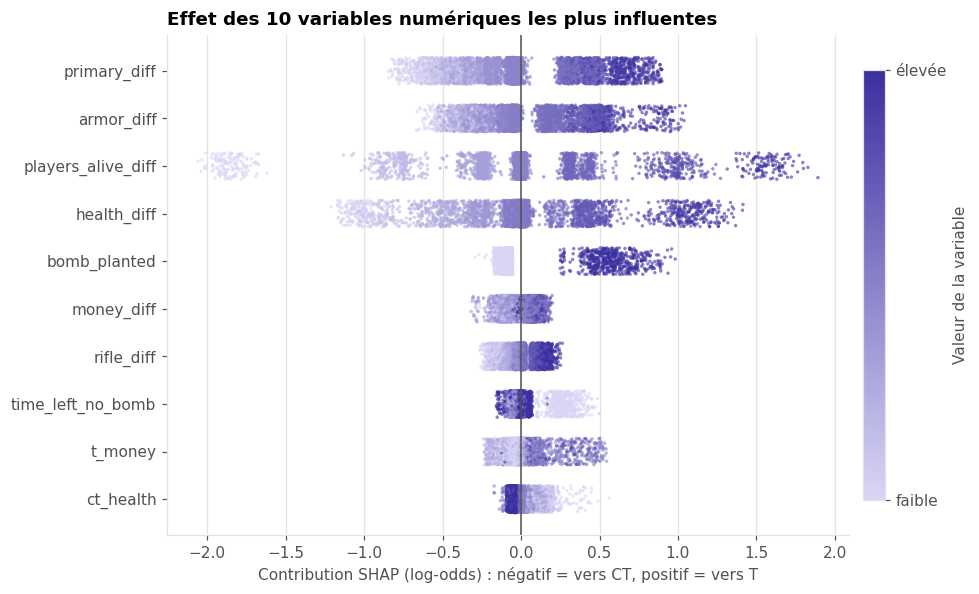

In [3]:
sample = shap_test.sample(5000, random_state=SEED).index
top10 = [c for c in importance.index if c != "map"][:10][::-1]
cmap = LinearSegmentedColormap.from_list("valeur", ["#d9d6f5", "#3b2fa0"])
rng = np.random.default_rng(SEED)

fig, ax = plt.subplots(figsize=(9, 5.5))
for y, feat in enumerate(top10):
    vals = features_test.loc[sample, feat].astype(float)
    lo, hi = vals.quantile(0.02), vals.quantile(0.98)
    norm = ((vals - lo) / (hi - lo if hi > lo else 1)).clip(0, 1)
    ax.scatter(shap_test.loc[sample, feat], y + rng.uniform(-0.28, 0.28, len(sample)),
               c=norm, cmap=cmap, s=5, alpha=0.6, linewidths=0)
ax.axvline(0, color=COLOR_TEXT_MUTED, linewidth=1)
ax.set_yticks(range(len(top10)), top10)
ax.set_xlabel("Contribution SHAP (log-odds) : négatif = vers CT, positif = vers T")
ax.set_title("Effet des 10 variables numériques les plus influentes")
ax.grid(axis="y", visible=False)
sm = plt.cm.ScalarMappable(cmap=cmap)
cbar = fig.colorbar(sm, ax=ax, fraction=0.03, pad=0.02, ticks=[0, 1])
cbar.ax.set_yticklabels(["faible", "élevée"])
cbar.set_label("Valeur de la variable")
plt.tight_layout()
save_fig(fig, "19_shap_effets")
plt.show()

## 3. Effet de trois variables clés

- **écart de joueurs vivants** : effet attendu très fort et monotone ;
- **écart d'armure** : résume l'équipement acheté ;
- **temps restant**, séparé selon la bombe : l'analyse exploratoire avait montré que son effet s'inverse quand la bombe est posée.

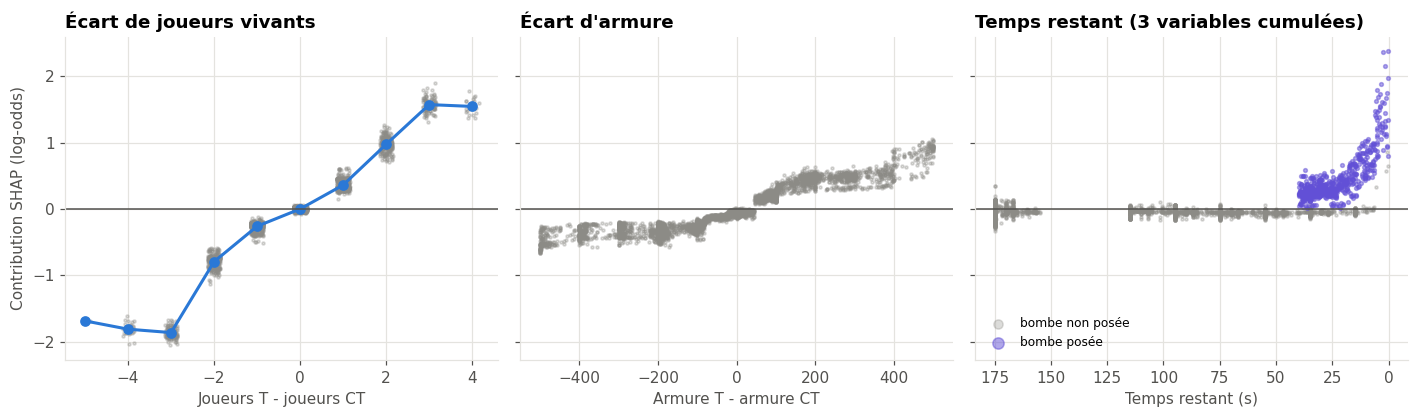

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
s = shap_test.loc[sample]
f = features_test.loc[sample]

alive = pd.DataFrame({"x": f["players_alive_diff"], "y": s["players_alive_diff"]})
means = alive.groupby("x")["y"].mean()
axes[0].scatter(alive["x"] + rng.uniform(-0.15, 0.15, len(alive)), alive["y"], s=4, alpha=0.3, color="#8c8b86")
axes[0].plot(means.index, means.values, color=COLOR_CT, linewidth=2, marker="o")
axes[0].set_xlabel("Joueurs T - joueurs CT")
axes[0].set_title("Écart de joueurs vivants")

axes[1].scatter(f["armor_diff"], s["armor_diff"], s=4, alpha=0.3, color="#8c8b86")
axes[1].set_xlabel("Armure T - armure CT")
axes[1].set_title("Écart d'armure")

bomb = f["bomb_planted"].astype(bool)
time_contrib = s["time_left"] + s["time_left_no_bomb"] + s["time_left_bomb"]
axes[2].scatter(f.loc[~bomb, "time_left"], time_contrib[~bomb], s=4, alpha=0.3, color="#8c8b86", label="bombe non posée")
axes[2].scatter(f.loc[bomb, "time_left"], time_contrib[bomb], s=6, alpha=0.5, color="#6250d6", label="bombe posée")
axes[2].invert_xaxis()
axes[2].set_xlabel("Temps restant (s)")
axes[2].set_title("Temps restant (3 variables cumulées)")
axes[2].legend(loc="lower left", fontsize=8, markerscale=3)

for ax in axes:
    ax.axhline(0, color=COLOR_TEXT_MUTED, linewidth=1)
axes[0].set_ylabel("Contribution SHAP (log-odds)")
plt.tight_layout()
save_fig(fig, "20_shap_dependances")
plt.show()

Pour le temps restant, les contributions des trois variables liées au temps (`time_left`, `time_left_no_bomb`, `time_left_bomb`) sont additionnées : c'est l'effet total du chrono sur la prédiction.

## 4. Expliquer une prédiction

Le round de de_inferno déjà présenté dans `07_evaluation_finale.ipynb` : la probabilité des T tombe à quelques pourcents, puis remonte au-dessus de 95 % après la pose de la bombe. On explique ses deux snapshots extrêmes.

In [5]:
test["proba"] = model.predict_proba(test)[:, 1]
rounds = test.groupby("round_id").agg(winner=("round_winner", lambda w: str(w.iloc[0])), n=("proba", "size"),
                                      swing=("proba", lambda p: p.max() - p.min()))
rounds = rounds[rounds["n"].between(5, 12)]
rid = rounds[rounds["winner"] == "T"]["swing"].idxmax()
r = test[test["round_id"] == rid].sort_values("snapshot_idx")
low_idx, high_idx = r["proba"].idxmin(), r["proba"].idxmax()

cols = ["map", "snapshot_idx", "time_left", "bomb_planted", "ct_players_alive", "t_players_alive",
        "ct_armor", "t_armor", "ct_money", "t_money", "proba"]
r[cols].round(3)

,map,snapshot_idx,time_left,bomb_planted,ct_players_alive,t_players_alive,ct_armor,t_armor,ct_money,t_money,proba
6950,de_inferno,0,174.92,False,5.0,5.0,146.0,0.0,22050.0,19450.0,0.351
6951,de_inferno,1,114.92,False,5.0,5.0,446.0,500.0,2100.0,450.0,0.490
6952,de_inferno,2,94.92,False,5.0,5.0,434.0,479.0,2100.0,450.0,0.427
6953,de_inferno,3,74.95,False,4.0,3.0,339.0,281.0,2400.0,600.0,0.192
6954,de_inferno,4,54.95,False,4.0,2.0,339.0,197.0,2700.0,500.0,0.060
6955,de_inferno,5,34.95,False,4.0,2.0,339.0,197.0,2700.0,500.0,0.061
6956,de_inferno,6,37.73,True,2.0,2.0,189.0,197.0,1000.0,1400.0,0.753
6957,de_inferno,7,17.73,True,1.0,2.0,82.0,197.0,500.0,1700.0,0.982


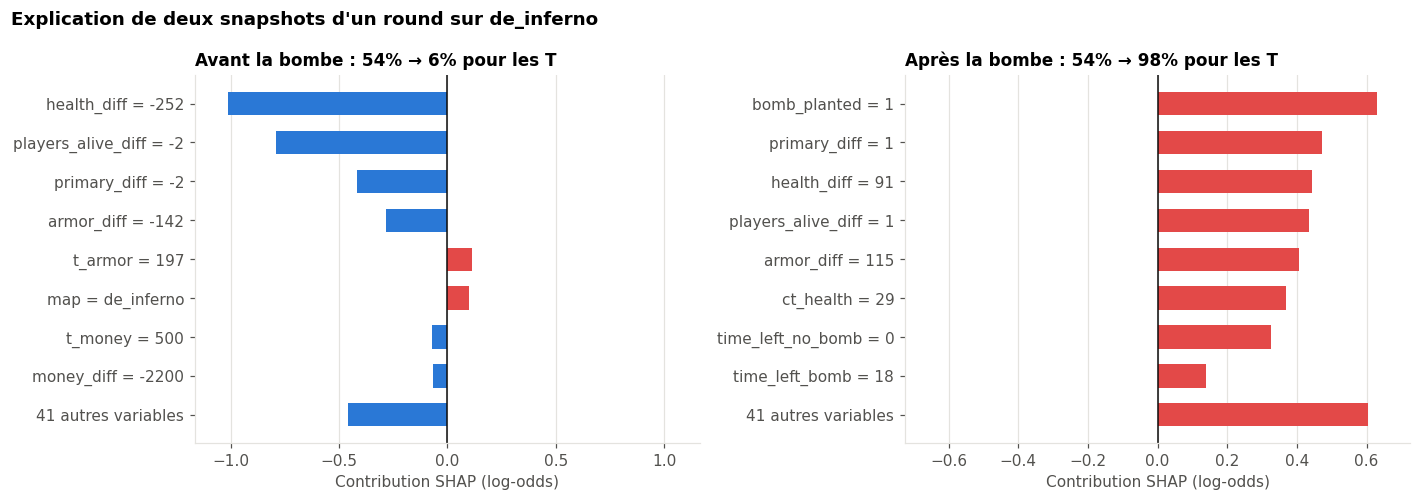

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
explanations = {}
for ax, idx, label in [(axes[0], low_idx, "Avant la bombe"), (axes[1], high_idx, "Après la bombe")]:
    table = explain_row(model, test.loc[[idx]], top=8).iloc[::-1]
    explanations[label] = table
    colors = [COLOR_T if c > 0 else COLOR_CT for c in table["contribution"]]
    names = [f"{v} = {x:.0f}" if isinstance(x, (int, float, np.floating)) else
             (f"{v} = {x}" if x != "" else v) for v, x in zip(table["variable"], table["valeur"])]
    ax.barh(names, table["contribution"], color=colors, height=0.6)
    ax.axvline(0, color=COLOR_TEXT, linewidth=1)
    lim = table["contribution"].abs().max() * 1.15
    ax.set_xlim(-lim, lim)
    ax.set_title(f"{label} : {table.attrs['proba_base']:.0%} → {table.attrs['proba_finale']:.0%} pour les T",
                 fontsize=11)
    ax.set_xlabel("Contribution SHAP (log-odds)")
    ax.grid(axis="y", visible=False)
fig.suptitle(f"Explication de deux snapshots d'un round sur {r['map'].iloc[0]}", x=0.01, ha="left",
             fontweight="bold")
plt.tight_layout()
save_fig(fig, "21_shap_explication_locale")
plt.show()

Rouge : contribution vers une victoire T ; bleu : vers une victoire CT. Le titre de chaque panneau donne la probabilité de départ (valeur de base, identique pour tous les snapshots) et la probabilité finale.

## 5. Résumé des résultats

In [7]:
print("=== Résumé ===")
print("Importance globale (moyenne |SHAP|, top 10) :")
for name, v in importance.head(10).items():
    print(f"   {name:<22}: {v:.3f} ({share[name]:.0%})")
print(f"Part des 5 premières variables : {share.head(5).sum():.0%}")
print("Effet moyen de l'écart de joueurs (log-odds) :", ", ".join(f"{int(k):+d} -> {v:+.2f}" for k, v in means.items()))
for label, table in explanations.items():
    main = table.iloc[::-1].head(3)
    print(f"{label} : proba {table.attrs['proba_finale']:.1%} | principales contributions : "
          + ", ".join(f"{v} ({c:+.2f})" for v, c in zip(main['variable'], main['contribution'])))

=== Résumé ===
Importance globale (moyenne |SHAP|, top 10) :
   primary_diff          : 0.303 (14%)
   armor_diff            : 0.261 (12%)
   players_alive_diff    : 0.240 (11%)
   health_diff           : 0.226 (10%)
   bomb_planted          : 0.136 (6%)
   money_diff            : 0.077 (3%)
   rifle_diff            : 0.067 (3%)
   time_left_no_bomb     : 0.066 (3%)
   t_money               : 0.064 (3%)
   map                   : 0.059 (3%)
Part des 5 premières variables : 53%
Effet moyen de l'écart de joueurs (log-odds) : -5 -> -1.69, -4 -> -1.81, -3 -> -1.86, -2 -> -0.80, -1 -> -0.26, +0 -> -0.00, +1 -> +0.36, +2 -> +0.97, +3 -> +1.57, +4 -> +1.55
Avant la bombe : proba 6.0% | principales contributions : health_diff (-1.01), players_alive_diff (-0.79), primary_diff (-0.42)
Après la bombe : proba 98.2% | principales contributions : bomb_planted (+0.63), primary_diff (+0.47), health_diff (+0.44)


## Conclusion

**Ce qui compte pour le modèle :** les quatre variables les plus influentes sont des écarts entre équipes : armes principales (`primary_diff`, 14 % de l'influence totale), armure (`armor_diff`, 12 %), joueurs vivants (`players_alive_diff`, 11 %) et santé (`health_diff`, 10 %). La bombe posée arrive en cinquième position (6 %). Ces cinq variables représentent 53 % de l'influence totale ; la carte ne pèse que 3 %. SHAP confirme les quatre premières variables de l'importance par impureté (`04_feature_engineering.ipynb`), dans un ordre légèrement différent.

**Sens des effets :** tous les écarts agissent dans le sens attendu : un avantage des T en équipement, armure, santé ou joueurs pousse la prédiction vers les T. L'effet de l'écart de joueurs est croissant et presque symétrique (−0,26 pour un joueur de retard, +0,36 pour un joueur d'avance, ±0,8 à 1 pour deux joueurs), puis plafonne au-delà de trois joueurs d'écart : ces situations sont rares et presque toujours décidées.

**Temps et bombe :** sans bombe, le chrono a une contribution proche de zéro : une fois connus les joueurs vivants et l'équipement, le temps restant apporte peu d'information. Avec la bombe posée, sa contribution devient positive et augmente à mesure que le temps s'écoule (jusqu'à environ +2,4 en log-odds dans les dernières secondes). Le modèle a donc appris l'interaction entre temps et bombe mise en évidence dans l'analyse exploratoire.

**Exemple de de_inferno :** à 6 %, la prédiction est tirée vers les CT par l'écart de santé (−252, contribution −1,01), le retard de deux joueurs (−0,79) et le manque d'armes principales (−0,42). À 98,2 %, la bombe est posée (+0,63), et les T ont pris l'avantage en armes principales (+0,47), en santé (+0,44) et en joueurs. Les explications correspondent à ce qu'un joueur de CS:GO lirait dans la situation, ce qui donne confiance dans le modèle.